In [1]:
import pybaseball as pyb
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")

# Pick our pitcher, for this instance I will pick Paul Skenes

In [2]:
pyb.playerid_lookup('skenes', 'paul')

mlb_id = pyb.playerid_lookup('skenes', 'paul')["key_mlbam"].iloc[0]
mlb_fname = pyb.playerid_lookup('skenes', 'paul')["name_first"].iloc[0].capitalize()
mlb_lname = pyb.playerid_lookup('skenes', 'paul')["name_last"].iloc[0].capitalize()

Gathering player lookup table. This may take a moment.


In [3]:
pitcher_stats = pyb.statcast_pitcher('2025-03-18', '2025-09-28', mlb_id)

Gathering Player Data


# Setting Colors

We will utilize the colors set by TJStats as I respect his work a lot.

@TJStats on Twitter/X

In [12]:
pitch_colors = {
    ## Fastballs ##
    'FF': {'color': '#FF007D', 'name': '4-Seam Fastball'},
    'FA': {'color': '#FF007D', 'name': 'Fastball'},
    'SI': {'color': '#98165D', 'name': 'Sinker'},
    'FC': {'color': '#BE5FA0', 'name': 'Cutter'},

    ## Offspeed ##
    'CH': {'color': '#F79E70', 'name': 'Changeup'},
    'FS': {'color': '#FE6100', 'name': 'Splitter'},
    'SC': {'color': '#F08223', 'name': 'Screwball'},
    'FO': {'color': '#FFB000', 'name': 'Forkball'},

    ## Sliders ##
    'SL': {'color': '#67E18D', 'name': 'Slider'},
    'ST': {'color': '#1BB999', 'name': 'Sweeper'},
    'SV': {'color': '#376748', 'name': 'Slurve'},

    ## Curveballs ##
    'KC': {'color': '#311D8B', 'name': 'Knuckle Curve'},
    'CU': {'color': '#3025CE', 'name': 'Curveball'},
    'CS': {'color': '#274BFC', 'name': 'Slow Curve'},
    'EP': {'color': '#648FFF', 'name': 'Eephus'},

    ## Others ##
    'KN': {'color': '#867A08', 'name': 'Knuckleball'},
    'PO': {'color': '#472C30', 'name': 'Pitch Out'},
    'UN': {'color': '#9C8975', 'name': 'Unknown'},
}

# Create a dictionary mapping pitch types to their colors
dict_color = dict(zip(pitch_colors.keys(), [pitch_colors[key]['color'] for key in pitch_colors]))

# Create a dictionary mapping pitch types to their colors
dict_pitch = dict(zip(pitch_colors.keys(), [pitch_colors[key]['name'] for key in pitch_colors]))

# Velocity Distribution Graph

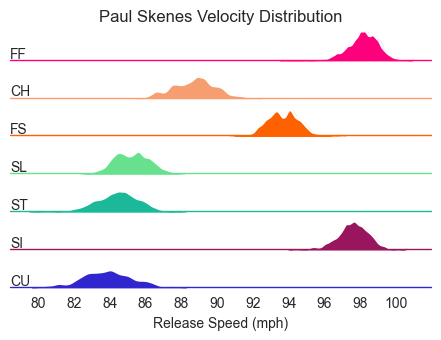

In [13]:
g = sns.FacetGrid(
    pitcher_stats,
    row="pitch_type",
    hue="pitch_type",
    aspect=10,
    height=.5,
    palette=dict_colour
)

g.map(
    sns.kdeplot,
    "release_speed",
    bw_adjust=.5,
    clip_on=False,
    fill=True,
    alpha=1,
    linewidth=1.5
)

g.map(
    sns.kdeplot,
    "release_speed",
    clip_on=False,
    color="w",
    lw=2,
    bw_adjust=.5
)

g.refline(
    y=0,
    linewidth=1,
    linestyle="-",
    color=None,
    clip_on=False
)

def label(x, color, label):
    ax = plt.gca()
    ax.text(
        0, .2, label,
        ha="left",
        va="center",
        transform=ax.transAxes
    )

g.map(label, "release_speed")

g.figure.subplots_adjust(hspace=.25)
g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)

plt.title(
    f"{mlb_fname} {mlb_lname} Velocity Distribution",
    y=8.5
)

plt.xlabel("Release Speed (mph)")
plt.xticks(range(80, 101, 2))

plt.show()

# Pie chart for pitch types

Check this over in the future. There seems to be a category titled pitch_category within the df already?

In [39]:
pitch_categories = {
    'FF': 'Fastball',
    'FA': 'Fastball',
    'SI': 'Fastball',
    'FC': 'Fastball',

    'CH': 'Offspeed',
    'FS': 'Offspeed',
    'SC': 'Offspeed',
    'FO': 'Offspeed',

    'SL': 'Slider',
    'ST': 'Slider',
    'SV': 'Slider',

    'KC': 'Curveball',
    'CU': 'Curveball',
    'CS': 'Curveball',
    'EP': 'Curveball',

    'KN': 'Other',
    'PO': 'Other',
    'UN': 'Other'
}

pitcher_stats["pitch_category"] = pitcher_stats["pitch_type"].map(pitch_categories)

category_colors = {
    "Fastball": "#7f58af",
    "Offspeed": "#64c5eb",
    "Slider": "#e84d8a",
    "Curveball": "#feb326",
    "Other": "#867A08"
}

In [18]:
pitch_table = (
    pitcher_stats
    .groupby("pitch_category")["release_speed"]
    .agg(["count", "mean"])
    .reset_index()
)

pitch_table["mean"] = pitch_table["mean"].round(1)

pitch_table

,pitch_category,count,mean
0,Curveball,145,83.9
1,Fastball,1507,98.1
2,Offspeed,747,91.5
3,Slider,649,84.7


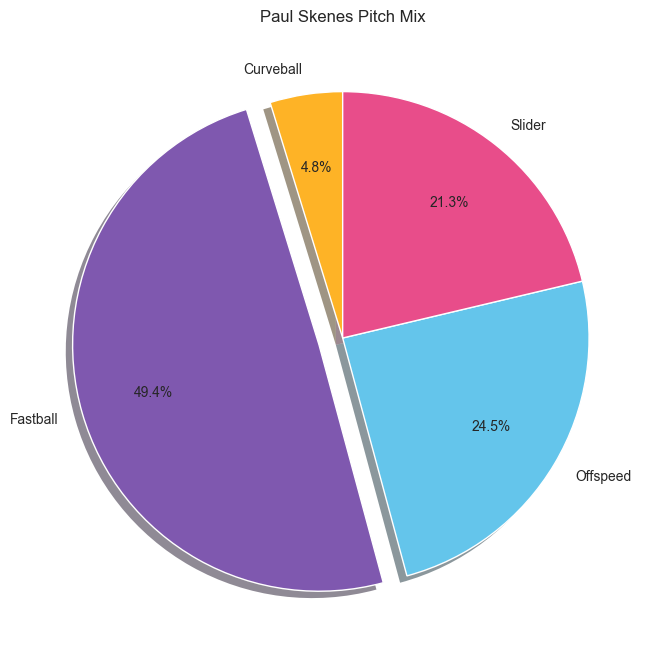

In [62]:
labels = pitch_table["pitch_category"]
sizes = pitch_table["count"]
colors = pitch_table["pitch_category"].map(category_colors)
explode = (0, 0.1, 0, 0)  

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    colors=colors,
    pctdistance=.7,
    labeldistance=1.1,
    explode=explode,
    startangle=90,
    shadow={'ox': -0.02, 'edgecolor': 'none','shade': 0.75}
)

ax.set_title(f"{mlb_fname} {mlb_lname} Pitch Mix")

plt.show()

In [71]:
pitcher_stats_filtered = pitcher_stats[
    pitcher_stats["pitch_category"].isin(pitch_table["pitch_category"])
]


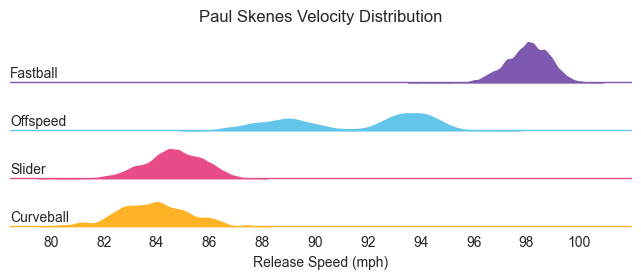

In [81]:
g = sns.FacetGrid(
    pitcher_stats_filtered,
    row="pitch_category",
    hue="pitch_category",
    aspect=10,
    height=.7,
    palette=category_colors
)

g.map(
    sns.kdeplot,
    "release_speed",
    bw_adjust=.5,
    clip_on=False,
    fill=True,
    alpha=1,
    linewidth=1.5
)

g.map(
    sns.kdeplot,
    "release_speed",
    clip_on=False,
    color="w",
    lw=2,
    bw_adjust=.5
)

g.refline(
    y=0,
    linewidth=1,
    linestyle="-",
    color=None,
    clip_on=False
)

def label(x, color, label):
    ax = plt.gca()
    ax.text(
        0, .2, label,
        ha="left",
        va="center",
        transform=ax.transAxes
    )

g.map(label, "release_speed")

g.figure.subplots_adjust(hspace=.1)
g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)

plt.title(
    f"{mlb_fname} {mlb_lname} Velocity Distribution",
    y=4.5
)

plt.xlabel("Release Speed (mph)")
plt.xticks(range(80, 101, 2))

plt.show()

In [68]:
pitcher_stats

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches,pitch_category
0,FF,2025-09-24,98.0,-2.26,5.61,"Skenes, Paul",668715,694973,strikeout,swinging_strike,...,1.41,1.09,1.09,23.9,8.323969,17.637232,22.804887,42.865697,21.441068,Fastball
1,CH,2025-09-24,89.4,-2.48,5.65,"Skenes, Paul",668715,694973,NaN,foul,...,2.41,1.44,1.44,20.4,24.418062,-27.950049,34.605614,30.523186,42.067772,Offspeed
2,FF,2025-09-24,97.7,-2.30,5.62,"Skenes, Paul",668715,694973,NaN,ball,...,1.44,1.06,1.06,22.1,NaN,NaN,NaN,NaN,NaN,Fastball
3,FF,2025-09-24,97.2,-2.27,5.60,"Skenes, Paul",668715,694973,NaN,called_strike,...,1.60,1.27,1.27,22.0,NaN,NaN,NaN,NaN,NaN,Fastball
4,FF,2025-09-24,97.7,-2.26,5.63,"Skenes, Paul",668715,694973,NaN,called_strike,...,1.34,1.11,1.11,26.4,NaN,NaN,NaN,NaN,NaN,Fastball
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3043,FF,2025-03-22,98.7,-2.43,5.42,"Skenes, Paul",656811,694973,double,hit_into_play,...,1.60,1.32,-1.32,NaN,NaN,NaN,NaN,NaN,NaN,Fastball
3044,FS,2025-03-22,93.4,-2.58,5.51,"Skenes, Paul",656811,694973,NaN,ball,...,2.45,1.22,-1.22,NaN,NaN,NaN,NaN,NaN,NaN,Offspeed
3045,FF,2025-03-22,98.1,-2.40,5.44,"Skenes, Paul",681297,694973,strikeout,called_strike,...,1.50,1.32,-1.32,NaN,NaN,NaN,NaN,NaN,NaN,Fastball
3046,FF,2025-03-22,98.7,-2.52,5.51,"Skenes, Paul",681297,694973,NaN,swinging_strike,...,1.22,1.19,-1.19,NaN,NaN,NaN,NaN,NaN,NaN,Fastball
